# Five ways to fix the idea

[`analysis.ipynb`](analysis.ipynb) found that buying the laggards of hot sectors doesn't beat the market in
the S&P 500, and that the *leaders* of hot sectors did better. This notebook asks whether a smarter version
of the idea works. It formulates five competing explanations for the failure, each grounded in published
research, and tests each one as a concrete strategy change.

Rebuilt by `uv run python -m usom.pipeline && uv run python -m usom.experiments`.

## Verdict

**None of the five improvements survives out-of-sample.** Filtering the laggards removes some bad ones,
but what's left at best matches the index and never beats it. Numbers are from the run of 2026-10-24.
Out-of-sample means Oct 2017 – Aug 2026, net of 10 bp costs.

| | Change to the idea | In-sample, chosen cell | Out-of-sample, same cell | Result |
|---|---|---|---|---|
| H1 | groups ranked on 3–12 months, laggards on the last month | +0.9%/yr, t = 0.5 (fails) | −0.8%/yr, t = −0.3 | rejected |
| H2 | quiet laggards instead of loud ones | +5.1%/yr, t = 2.6 (passes) | −0.7%/yr, t = −0.3 | not confirmed |
| H3 | laggards from broad rallies instead of narrow ones | +4.1%/yr, t = 1.7 (fails) | +3.5%/yr, t = 0.8 | not confirmed |
| H4 | hot-group leaders instead of plain stock momentum | +0.9%/yr, t = 0.5 (fails) | −1.3%/yr, t = −0.7 | rejected |
| H5 | laggards in volatile markets, leaders otherwise | +5.3%/yr, t = 2.5 (passes) | +2.0%/yr, t = 0.9 | not confirmed |

After correcting for five tests, every out-of-sample p-value is 0.87 or higher.

**The improved strategy** blends H2 and H5, the two that passed in-sample, by the rule fixed in advance.
Out-of-sample it made **13.7%/yr**, against 12.0% for the equal-weight index: +1.5%/yr, t = 0.7. That's a
little better than the original idea (13.1%), but behind hot-sector leaders (15.6%) and SPY (14.9%). Its
factor alpha is +0.8%/yr (t = 0.3), indistinguishable from zero.

**What held up in both periods.** These are exploratory, found partly by looking at out-of-sample data:

- **Avoid "loud" laggards.** Laggards whose fall came with a jump in stock-specific volatility (a proxy for
  news) trailed the index by a median 2.9%/yr in-sample and 2.2%/yr out-of-sample. Within industries,
  quiet beat loud in 92% of in-sample and 75% of out-of-sample cells. This is a filter, not an edge: the
  quiet laggards still trail the index (−0.2% and −1.6%/yr).
- **After a falling year, laggards beat leaders** inside hot groups in both periods: +11.6%/yr in-sample and
  +3.0%/yr out-of-sample. That matches the momentum-crash literature, but rests on only 25 and 15 such
  months, and the switching rule fixed in advance didn't survive.
- **No laggard sub-basket beat the index in either period.** Quiet, loud, broad-rally and narrow-rally
  laggards all have negative medians, from −0.2% to −2.9%/yr.

**Bottom line.** Across S&P 500 stocks from 2005 to 2026, none of the versions of "buy the laggards of hot
sectors" tested here beats owning the index. If you want exposure to a hot theme, its leaders, or simply
the index, did better than its laggards. If you do buy a laggard, skip the ones that fell on news.

**Not tested, because it needs data that isn't free:**
- Analyst earnings revisions, which Da, Liu & Schaumburg use to separate fundamental moves from noise.
- Real news timestamps.
- Mid and small caps, where Chan's (2003) news/no-news effects are strongest.
- Weekly horizons.

## The protocol (fixed before any of these results existed)

The same data, costs (10 bp one-way) and execution lag as the main study. Each hypothesis names **one
long/short spread** and a **family of cells** (parameter variant × sector definition × holding period).

1. **Choose in-sample.** On the early years (2005–2017), take the cell with the highest Newey–West t-stat.
   The hypothesis *passes in-sample* if that t ≥ 2.
2. **Test out-of-sample.** Run that single cell on Oct 2017 – Aug 2026, years it has never seen.
3. **Correct for testing five ideas at once.** A hypothesis is *confirmed* only if its out-of-sample
   one-sided p-value is still below 5% after a Holm–Bonferroni adjustment across the five.
4. **Show every cell.** Every cell is reported, not just the chosen one.
5. **The "improved strategy" is fixed in advance.** It is an equal-weight blend of the long legs of every
   hypothesis that passes in-sample, at their chosen cells, judged only out-of-sample.

One caution cuts across everything: the in-sample years are missing many failed companies, which flatters
laggard strategies there (see the main notebook). So a laggard idea passing in-sample is weaker evidence
than it looks, and the out-of-sample test is the one that counts.

## The hypotheses

**H1. Horizon mismatch.** The original rule used one lookback for two different effects. *Industry
momentum* (strong industries keep outperforming) is strongest over 6–12 months (Moskowitz & Grinblatt,
1999). *Within-industry reversal* (last month's losers inside an industry bounce back, largely because
someone paid for liquidity to sell them) is a one-month effect, and stronger than the market-wide version
(Hameed & Mian, 2015; Da, Liu & Schaumburg, 2014).
*Test:* rank groups on 3/6/12-month returns, but pick laggards on the last month only.
*Spread:* hot-group laggards − equal-weight index.

**H2. News vs. noise.** Losers that fell on news tend to keep drifting down, while those that fell without
news tend to reverse (Chan, 2003). There's no free news feed for 1998–2026, so a jump in a stock's
market-adjusted volatility over the lookback, relative to the prior year, stands in for news.
*Spread:* quiet laggards (abnormal volatility at or below the month's median) − loud laggards.

**H3. Rally breadth.** If a whole industry rerates on a shared driver, information spreads slowly to the
names that haven't moved yet (Hou, 2007), and laggards should catch up. If a few names capture the theme
(winner-take-most), the laggards were left behind for a reason.
*Breadth* is the share of a group's members that beat the median stock over the lookback. The broad/narrow
threshold is the in-sample median among hot groups.
*Spread:* laggards in broad-rally hot groups − laggards in narrow-rally hot groups.

**H4. Leaders, not laggards.** The main study's strongest pattern was the opposite of the idea: inside hot
groups, the leaders won. Is that anything beyond ordinary stock momentum (Jegadeesh & Titman, 1993), which
it partly is by construction?
*Spread:* hot-group leaders − the strongest third of the whole index over the same lookback.

**H5. Market regime.** Reversal profits are a reward for providing liquidity, and are largest when
markets are volatile or have fallen (Nagel, 2012; Hameed & Mian, 2015). Momentum crashes in rebounds after
declines (Cooper, Gutierrez & Hameed, 2004; Daniel & Moskowitz, 2016). So hold hot-group laggards when the
market is volatile (trailing 3-month volatility above its own historical median, using only past data) or
has fallen over 12 months, and hold hot-group leaders otherwise.
*Spread:* the switching strategy − always holding hot-group leaders.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from usom import analysis as A
from usom import experiments as E
from usom import plots
from usom.backtest import next_month_end
from usom.config import StudyConfig
from usom.metrics import nw_tstat

warnings.filterwarnings("ignore", category=FutureWarning)
plots.use_style()
cfg = StudyConfig()
R = A.load_results()
X = E.load_experiments()
exp, state, monthly, returns = X["experiments"], X["market_state"], R["monthly"], R["returns"]
W = A.windows(monthly, cfg)
IS, OOS = W["in_sample"], W["out_of_sample"]
board = E.scoreboard(exp, W)

## Scoreboard

In [2]:
show = board[
    [
        "title",
        "spread",
        "variant",
        "scheme",
        "holding",
        "is_ann",
        "is_t",
        "passes_is",
        "oos_ann",
        "oos_t",
        "oos_p_holm",
        "confirmed",
        "oos_median_all_cells",
        "oos_share_positive",
        "cells",
    ]
]
show.style.format(
    {
        "is_ann": "{:+.1%}",
        "is_t": "{:.2f}",
        "oos_ann": "{:+.1%}",
        "oos_t": "{:.2f}",
        "oos_p_holm": "{:.3f}",
        "oos_median_all_cells": "{:+.1%}",
        "oos_share_positive": "{:.0%}",
    }
)

,title,spread,variant,scheme,holding,is_ann,is_t,passes_is,oos_ann,oos_t,oos_p_holm,confirmed,oos_median_all_cells,oos_share_positive,cells
hypothesis,,,,,,,,,,,,,,,
H1,Horizon mismatch,hot_laggards − universe,groups 3m / stocks 1m,sector,3,+0.9%,0.49,False,-0.8%,-0.35,1.000,False,-0.3%,41%,27
H2,News vs noise,hot_laggards_quiet − hot_laggards_loud,lookback 3m,industry,6,+5.1%,2.60,True,-0.7%,-0.31,1.000,False,-0.5%,44%,36
H3,Rally breadth,hot_laggards_broad − hot_laggards_narrow,lookback 3m,cluster,3,+4.1%,1.69,False,+3.5%,0.83,0.872,False,+0.8%,61%,36
H4,"Leaders, not laggards",hot_leaders − universe_leaders,lookback 1m,industry,3,+0.9%,0.48,False,-1.3%,-0.70,1.000,False,+1.2%,69%,36
H5,Market regime,switch − hot_leaders,"lookback 6m, laggards in volatile market",sector,3,+5.3%,2.47,True,+2.0%,0.94,0.872,False,-0.2%,40%,72


`is_*` is the cell chosen in-sample. `oos_*` is the same cell on the out-of-sample years.
`oos_median_all_cells` and `oos_share_positive` summarize the whole family out-of-sample, as a check that
the result doesn't hinge on one parameter choice.

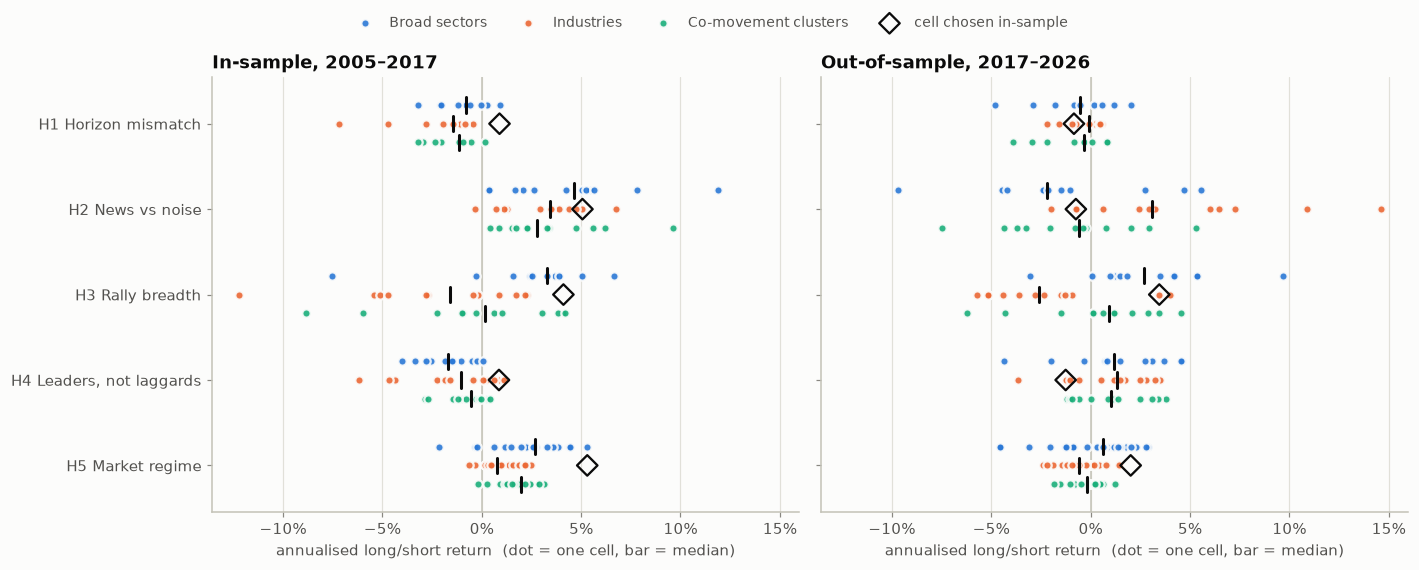

In [3]:
names = [f"{h.key} {h.title}" for h in E.HYPOTHESES]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True, sharex=True)
for ax, win in zip(axes, [IS, OOS], strict=True):
    cells = pd.concat(
        [E.spread_cells(exp, h, win).assign(spread=f"{h.key} {h.title}") for h in E.HYPOTHESES]
    )
    chosen = cells.merge(
        board.reset_index().assign(spread=lambda d: d.hypothesis + " " + d.title)[
            ["spread", "variant", "scheme", "holding"]
        ],
        on=["spread", "variant", "scheme", "holding"],
    )
    plots.spread_strips(
        cells,
        f"{win.name.capitalize()}, {win.start:%Y}–{win.end:%Y}",
        order=names,
        highlight=chosen,
        ax=ax,
        legend=False,
    )
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncols=4, fontsize=9, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

Each dot is one cell of a hypothesis' family. A real effect shows up as a whole cloud sitting to the right
of zero in **both** panels, not just a single dot.

### Where the H2 and H3 spreads come from

A long/short spread can be positive because the long leg is good, or because the short leg is bad. For a
strategy you would actually buy, only the first helps. Here is each leg against the equal-weight index,
as the median over all cells and the share of cells beating the index:

In [4]:
legs_rows = []
for key, basket in [
    ("H2", "hot_laggards_quiet"),
    ("H2", "hot_laggards_loud"),
    ("H3", "hot_laggards_broad"),
    ("H3", "hot_laggards_narrow"),
    ("H2", "hot_laggards"),
]:
    h = E.Hypothesis(key, "", "", basket, "universe")
    for win in (IS, OOS):
        c = E.spread_cells(exp, h, win)
        for scheme, g in [("all", c), *c.groupby("scheme")]:
            legs_rows.append(
                {
                    "leg": basket,
                    "scheme": scheme,
                    "window": win.name,
                    "median_vs_index": g["ann"].median(),
                    "share_beating_index": (g["ann"] > 0).mean(),
                }
            )
legs_tbl = pd.DataFrame(legs_rows)
legs_tbl[legs_tbl.scheme == "all"].pivot_table(
    index="leg", columns="window", values=["median_vs_index", "share_beating_index"], sort=False
).style.format("{:+.1%}", subset=["median_vs_index"]).format(
    "{:.0%}", subset=["share_beating_index"]
)

## Inside the hypotheses

### H1: one-month laggards inside long-horizon hot groups

In [5]:
h1 = E.spread_cells(exp, E.BY_KEY["H1"], OOS)
h1_is = E.spread_cells(exp, E.BY_KEY["H1"], IS)
t = h1.merge(h1_is, on=["variant", "scheme", "holding"], suffixes=("_oos", "_is"))
t.pivot_table(
    index=["variant", "holding"], columns="scheme", values=["ann_is", "ann_oos"]
).style.format("{:+.1%}")

### H5: does the market's mood decide between laggards and leaders?

The spread between hot-group laggards and leaders (1-month holds, averaged over all sector definitions
and lookbacks), split by the market state at formation:

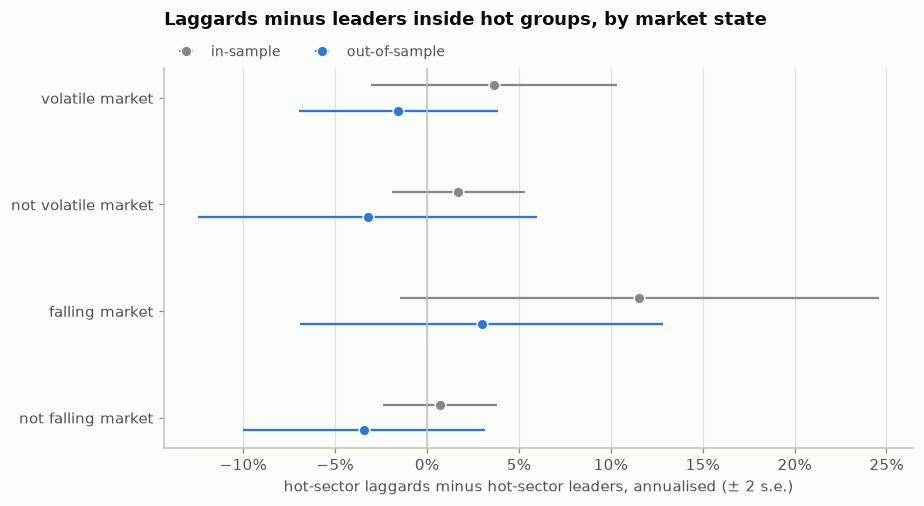

In [6]:
lag = returns[(returns.holding == 1) & (returns.basket == "hot_laggards")]
lead = returns[(returns.holding == 1) & (returns.basket == "hot_leaders")]
key = ["scheme", "lookback", "month"]
spread = (lag.set_index(key)["net"] - lead.set_index(key)["net"]).groupby("month").mean()
st = state.copy()
st.index = next_month_end(st.index)
rows = []
for flag, label in [("high_vol", "volatile market"), ("down", "falling market")]:
    for win in (IS, OOS):
        s = win(spread)
        f = st[flag].reindex(s.index)
        for value, name in [(True, label), (False, f"not {label}")]:
            x = s[(f == value).fillna(False).astype(bool)].dropna()
            mean, tstat = nw_tstat(x, lags=1)
            rows.append(
                {
                    "state": name,
                    "window": win.name,
                    "mean": mean,
                    "se": mean / tstat,
                    "months": len(x),
                }
            )
tbl = pd.DataFrame(rows)
plots.state_dots(tbl, "Laggards minus leaders inside hot groups, by market state")
plt.show()
tbl.assign(ann=tbl["mean"] * 12).pivot_table(
    index="state", columns="window", values=["ann", "months"], sort=False
).style.format("{:.3g}")

### H4: is "hot-group leaders" just momentum?

Factor regression of the chosen H4 cell out-of-sample (FF5 + momentum + short-term reversal). A large
`Mom` loading with alpha near zero would mean it's ordinary momentum in a sector wrapper.

In [7]:
b4 = board.loc["H4"]
lb = int(b4["variant"].split()[1].rstrip("m"))
c4 = {"scheme": b4["scheme"], "lookback": lb, "holding": int(b4["holding"])}
rows = {}
for k in ["hot_leaders", "universe_leaders", "hot_laggards", "universe"]:
    reg = A.factor_table(OOS(A.series(returns, **c4, basket=k)), monthly, lags=c4["holding"])
    rows[plots.BASKET_NAMES[k]] = pd.concat(
        [reg["coef"], pd.Series({"t(alpha)": reg.loc["alpha", "t"], "R²": reg.attrs["r2"]})]
    )
pd.DataFrame(rows).T.style.format("{:.2f}").format({"alpha": "{:+.1%}"})

,alpha,Mkt-RF,SMB,HML,RMW,CMA,Mom,ST_Rev,t(alpha),R²
Hot-sector leaders,-1.5%,0.862915,0.176518,0.343249,-0.142572,-0.239205,-0.016784,0.004124,-0.496198,0.769064
"Leaders, whole index",-1.0%,0.890044,0.235870,0.206184,0.055142,0.003579,0.048452,0.100511,-0.625073,0.868006
Hot-sector laggards,-3.1%,0.895539,0.242255,0.197085,0.086917,0.050434,-0.070342,0.067503,-1.520756,0.835358
Equal-weight S&P 500,-0.1%,0.910354,0.183791,0.185286,0.071624,0.134043,-0.012053,0.241678,-0.071338,0.893928


## The improved strategy

In [8]:
passing = board[board["passes_is"]]


def leg(key):
    row = board.loc[key]
    e = exp[
        (exp.hypothesis == key)
        & (exp.variant == row["variant"])
        & (exp.scheme == row["scheme"])
        & (exp.holding == row["holding"])
        & (exp.basket == E.BY_KEY[key].long)
    ]
    return e.set_index("month")["net"]


if passing.empty:
    display(
        Markdown(
            "**No hypothesis passed in-sample, so by the protocol there is no improved "
            "strategy to test.** The exploratory comparison below is labelled as such."
        )
    )
else:
    display(
        Markdown(
            "Passed in-sample and blended: "
            + ", ".join(
                f"**{k}** ({r['title']}: {r['variant']}, {r['scheme']}, hold {r['holding']}m)"
                for k, r in passing.iterrows()
            )
        )
    )

Passed in-sample and blended: **H2** (News vs noise: lookback 3m, industry, hold 6m), **H5** (Market regime: lookback 6m, laggards in volatile market, sector, hold 3m)

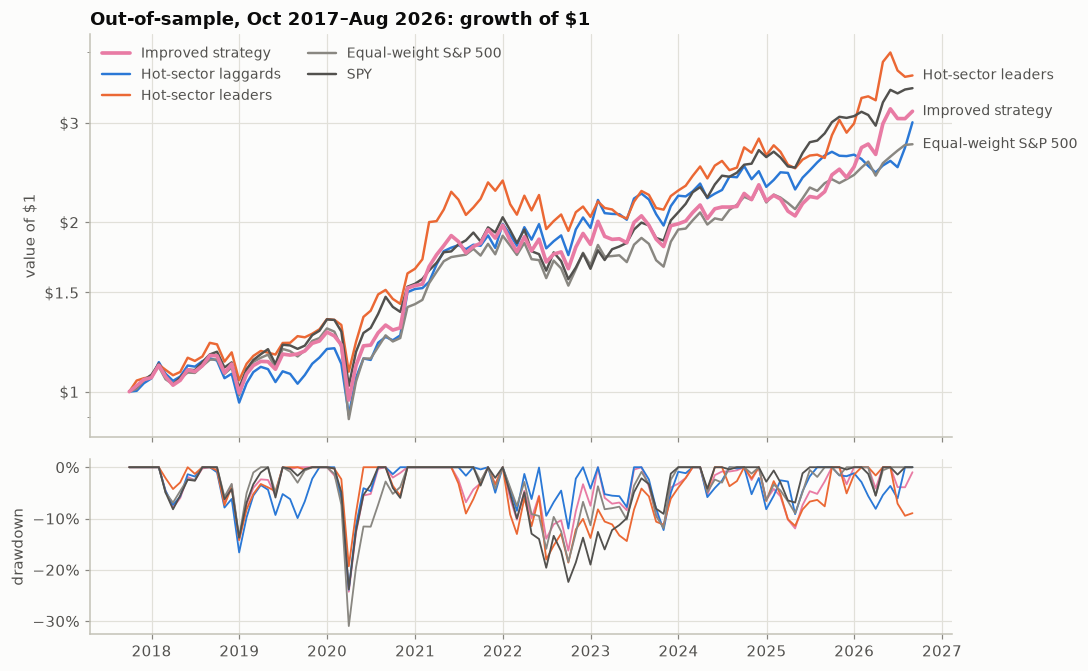

,cagr,vol,sharpe,max_dd,excess_ann,excess_t,months
Improved strategy,+13.7%,18.6%,0.65,-24%,+1.5%,0.71,107
Hot-sector laggards,+13.1%,19.1%,0.61,-24%,+1.1%,0.39,107
Hot-sector leaders,+15.6%,19.4%,0.71,-19%,+3.3%,0.97,107
Equal-weight S&P 500,+12.0%,18.3%,0.58,-31%,+0.0%,nan,107
SPY,+14.9%,16.9%,0.76,-24%,+2.3%,1.13,107


In [9]:
original = {"scheme": "sector", "lookback": 6, "holding": 3}  # the main study's in-sample pick
legs = (
    pd.concat({k: leg(k) for k in passing.index}, axis=1, sort=True) if not passing.empty else None
)
improved = legs.mean(axis=1, skipna=False) if legs is not None else None
curves = {}
if improved is not None:
    curves["improved"] = OOS(improved)
curves["hot_laggards"] = OOS(A.series(returns, **original, basket="hot_laggards"))
curves["hot_leaders"] = OOS(A.series(returns, **original, basket="hot_leaders"))
curves["universe"] = OOS(A.series(returns, **original, basket="universe"))
curves["spy"] = OOS(monthly["spy"]).reindex(curves["universe"].index)
main_line = "improved" if improved is not None else "hot_laggards"
plots.growth_chart(
    curves, f"Out-of-sample, {OOS.start:%b %Y}–{OOS.end:%b %Y}: growth of $1", main=main_line
)
plt.show()
stats = {
    plots.BASKET_NAMES[k]: A.summarize(v, monthly["RF"], curves["universe"], lags=3)
    for k, v in curves.items()
}
pd.DataFrame(stats).T.style.format(
    {
        "cagr": "{:+.1%}",
        "vol": "{:.1%}",
        "sharpe": "{:.2f}",
        "max_dd": "{:.0%}",
        "excess_ann": "{:+.1%}",
        "excess_t": "{:.2f}",
        "months": "{:.0f}",
    }
)

For comparison, the original idea is shown at the main study's in-sample pick (broad sectors, 6-month
lookback, 3-month hold), together with that cell's hot-group leaders, the equal-weight index and SPY.

In [10]:
if improved is not None:
    rows = {}
    for name, r in [
        ("Improved strategy", improved),
        ("Hot-sector laggards (original)", A.series(returns, **original, basket="hot_laggards")),
    ]:
        reg = A.factor_table(OOS(r), monthly, lags=3)
        rows[name] = pd.concat(
            [reg["coef"], pd.Series({"t(alpha)": reg.loc["alpha", "t"], "R²": reg.attrs["r2"]})]
        )
    display(Markdown("Factor regressions out-of-sample (alpha annualised):"))
    display(pd.DataFrame(rows).T.style.format("{:.2f}").format({"alpha": "{:+.1%}"}))

Factor regressions out-of-sample (alpha annualised):

,alpha,Mkt-RF,SMB,HML,RMW,CMA,Mom,ST_Rev,t(alpha),R²
Improved strategy,+0.8%,0.945740,0.093617,0.224957,-0.122890,0.074419,0.096376,0.169200,0.338218,0.804018
Hot-sector laggards (original),+2.1%,0.868789,0.044002,0.044698,-0.054565,0.439729,-0.220254,0.252303,0.762897,0.786646


## References

- Chan, W. S. (2003). Stock price reaction to news and no-news: drift and reversal after headlines.
  *Journal of Financial Economics*, 70(2), 223–260.
- Cooper, M. J., Gutierrez, R. C., & Hameed, A. (2004). Market states and momentum. *Journal of Finance*,
  59(3), 1345–1365.
- Da, Z., Liu, Q., & Schaumburg, E. (2014). A closer look at the short-term return reversal.
  *Management Science*, 60(3), 658–674.
- Daniel, K., & Moskowitz, T. J. (2016). Momentum crashes. *Journal of Financial Economics*, 122(2),
  221–247.
- Hameed, A., & Mian, G. M. (2015). Industries and stock return reversals. *Journal of Financial and
  Quantitative Analysis*, 50(1–2), 89–117.
- Hou, K. (2007). Industry information diffusion and the lead-lag effect in stock returns. *Review of
  Financial Studies*, 20(4), 1113–1138.
- Jegadeesh, N., & Titman, S. (1993). Returns to buying winners and selling losers. *Journal of Finance*,
  48(1), 65–91.
- Moskowitz, T. J., & Grinblatt, M. (1999). Do industries explain momentum? *Journal of Finance*, 54(4),
  1249–1290.
- Nagel, S. (2012). Evaporating liquidity. *Review of Financial Studies*, 25(7), 2005–2039.